<a href="https://colab.research.google.com/github/Divyesh-SP/DSA0405-FUNDAMENTALS-OF-DATA-SCIENCE/blob/main/DSA04_CO4_Statistical_Inference_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DSA04 CO4 — Statistical Inference
Run all cells in Google Colab. Synthetic teaching data; seed 42. Tables and figures are generated automatically.

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path
import json, datetime
from IPython.display import display
rng=np.random.default_rng(42)
OUT=Path('CO4_outputs'); OUT.mkdir(exist_ok=True)
def show(name, rows):
    d=pd.DataFrame(rows); display(d.round(5)); d.to_csv(OUT/(name+'.csv'),index=False)
def plot(name):
    plt.tight_layout(); plt.savefig(OUT/(name+'.png'),dpi=140); plt.show()


## Task 1 — Formulate inference problems
Population: eligible platform learners; unit: learner. Treatment minus control is the parameter, estimated by the difference in sample means (binary means are proportions). Two-sided tests detect benefit or harm. Alpha = .05; confidence = 95%. Thresholds below are illustrative planning choices, not supplied by the platform.

In [ ]:
spec={'Onboarding':('binary',.02),'Video':('continuous',5),'Quiz':('continuous',2),'Reminder':('binary',.02)}
show('plan',[dict(experiment=e,metric_type=t,H0='difference = 0',H1='difference != 0',alpha=.05,confidence=.95,threshold=h) for e,(t,h) in spec.items()])
predictions={'bootstrap':'Similar; bootstrap may be wider due to skew','metrics':'About one of 20','width':'0.707 times when n doubles','significance':'Onboarding and Quiz predicted, without inspecting outcomes'}
(OUT/'predictions.json').write_text(json.dumps({'recorded_at':str(datetime.datetime.now()),**predictions},indent=2))
print(predictions)


,experiment,metric_type,H0,H1,alpha,confidence,threshold
0,Onboarding,binary,difference = 0,difference != 0,0.05,0.95,0.02
1,Video,continuous,difference = 0,difference != 0,0.05,0.95,5.00
2,Quiz,continuous,difference = 0,difference != 0,0.05,0.95,2.00
3,Reminder,binary,difference = 0,difference != 0,0.05,0.95,0.02


{'bootstrap': 'Similar; bootstrap may be wider due to skew', 'metrics': 'About one of 20', 'width': '0.707 times when n doubles', 'significance': 'Onboarding and Quiz predicted, without inspecting outcomes'}


## Generate input data
The generator writes the truth separately; do not inspect that file until the last cell. Each experiment has 25,000 unique learners. Flags represent pre-established account-quality metadata. Quiz non-attempts are missing, so quiz inference is conditional on attempting; it is not automatically an intention-to-treat effect.

In [ ]:
def generate():
    truth=dict(zip(spec,[.025,0,1.0,0]))
    frames=[]
    for i,(e,(typ,_)) in enumerate(spec.items()):
        N=25000; g=rng.binomial(1,.48,N); effect=truth[e]
        base={'Onboarding':.35,'Reminder':.42}.get(e)
        if typ=='binary': y=rng.binomial(1,base+effect*g).astype(float)
        elif e=='Video': y=rng.lognormal(3.5,1.1,N)+effect*g
        else: y=np.clip(rng.normal(65,12,N)+effect*g,0,100)
        d=pd.DataFrame(dict(user_id=np.arange(N)+i*N,experiment=e,group=g,outcome=y,country=rng.choice(['India','UK','US'],N),device=rng.choice(['Mobile','Desktop'],N),earlier_courses=rng.poisson(2,N),assignment_date=pd.Timestamp('2025-01-01')+pd.to_timedelta(rng.integers(0,14,N),unit='D'),signup_date=pd.Timestamp('2024-12-01')+pd.to_timedelta(rng.integers(0,30,N),unit='D'),bot=rng.random(N)<.005,idle=rng.random(N)<.01))
        if e=='Video': d.loc[d.bot|d.idle,'outcome']*=20
        if e=='Quiz': d.loc[rng.random(N)<.12,'outcome']=np.nan
        dup=d.sample(50,random_state=42).copy(); dup.group=1-dup.group
        frames.extend([d,dup])
    (OUT/'true_effects.json').write_text(json.dumps(truth))
    return pd.concat(frames,ignore_index=True)
raw=generate(); raw.to_csv(OUT/'raw.csv',index=False); print(raw.shape,raw.user_id.nunique()); display(raw.head())


(100200, 11) 100000


,user_id,experiment,group,outcome,country,device,earlier_courses,assignment_date,signup_date,bot,idle
0,0,Onboarding,1,1.0,US,Mobile,5,2025-01-14,2024-12-24,False,False
1,1,Onboarding,0,1.0,US,Desktop,2,2025-01-09,2024-12-26,False,False
2,2,Onboarding,1,1.0,UK,Mobile,2,2025-01-06,2024-12-26,False,False
3,3,Onboarding,1,0.0,UK,Desktop,1,2025-01-03,2024-12-21,False,False
4,4,Onboarding,0,0.0,India,Mobile,3,2025-01-08,2024-12-23,False,False


## Task 2 — Preparation and assumptions
Exclude conflicting assignments rather than choosing a group based on outcomes. Remove flagged bots and idle video accounts; retain missing quiz counts and use available cases. Balance is diagnostic, not proof of randomization. Independence follows from simulated learner-level assignment.

,stage,rows,missing
0,raw,100200,2966
1,conflicts removed,99800,2956
2,flags removed,99057,2940
3,complete cases,96117,0


count       mean         std
experiment group                              
Onboarding 0      12989   0.352221    0.477681
           1      12061   0.378658    0.485073
Quiz       0      11649  64.953669   11.997952
           1      10435  65.931290   11.946324
Reminder   0      13075   0.425774    0.494479
           1      11975   0.422797    0.494024
Video      0      13045  80.871566  394.228930
           1      12005  78.050507  285.431916

count       mean        std
experiment group                             
Onboarding 0      12863   0.352406   0.477738
           1      11963   0.378751   0.485096
Quiz       0      11543  64.965398  11.995361
           1      10332  65.958694  11.952129
Reminder   0      12961   0.425507   0.494439
           1      11866   0.422720   0.494013
Video      0      12801  60.373937  95.172322
           1      11788  61.237066  96.562613

Onboarding


group,0,1
country,,
India,0.330638,0.328680
UK,0.336313,0.328179
US,0.333048,0.343141


group,0,1
device,,
Desktop,0.499495,0.499289
Mobile,0.500505,0.500711


,earlier_courses
group,
0,1.982352
1,2.018474


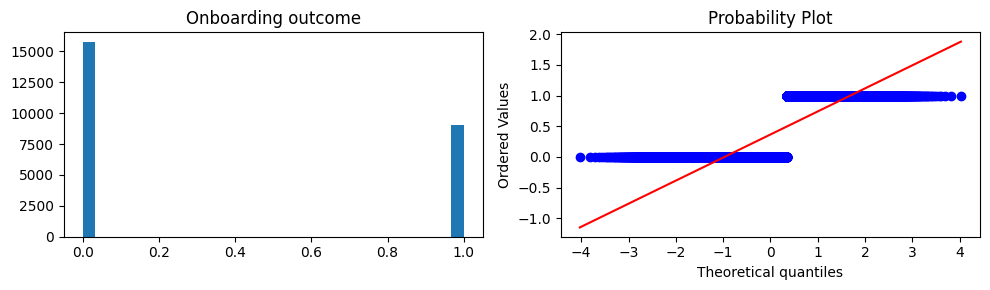

Quiz


group,0,1
country,,
India,0.328771,0.330430
UK,0.331370,0.334688
US,0.339860,0.334882


group,0,1
device,,
Desktop,0.499524,0.513066
Mobile,0.500476,0.486934


,earlier_courses
group,
0,2.007104
1,2.001452


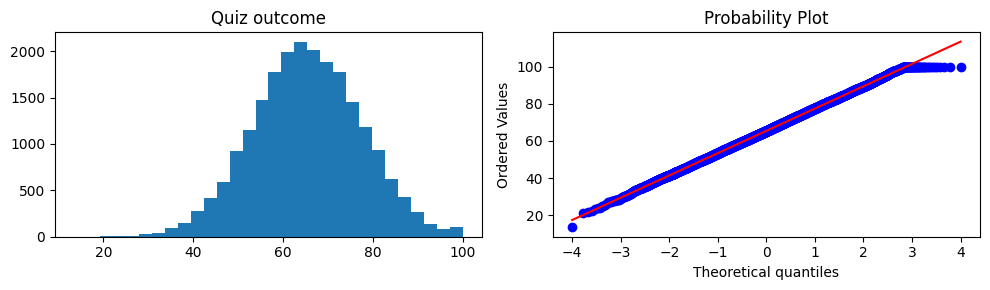

Reminder


group,0,1
country,,
India,0.331919,0.328670
UK,0.333308,0.337603
US,0.334774,0.333727


group,0,1
device,,
Desktop,0.495101,0.503287
Mobile,0.504899,0.496713


,earlier_courses
group,
0,2.008487
1,2.017023


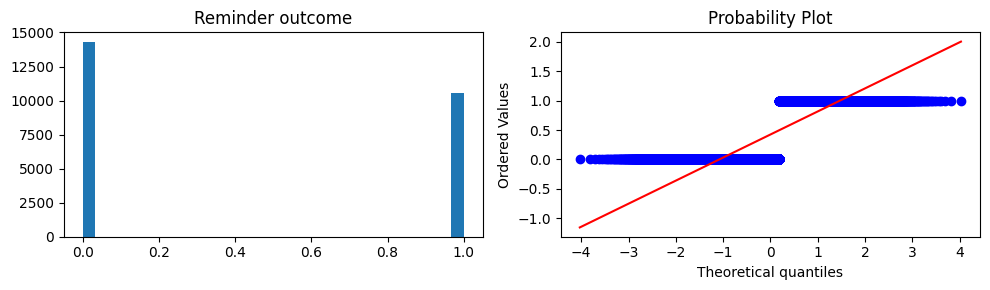

Video


group,0,1
country,,
India,0.336536,0.325840
UK,0.333958,0.337377
US,0.329506,0.336783


group,0,1
device,,
Desktop,0.496289,0.500763
Mobile,0.503711,0.499237


,earlier_courses
group,
0,2.002187
1,1.981591


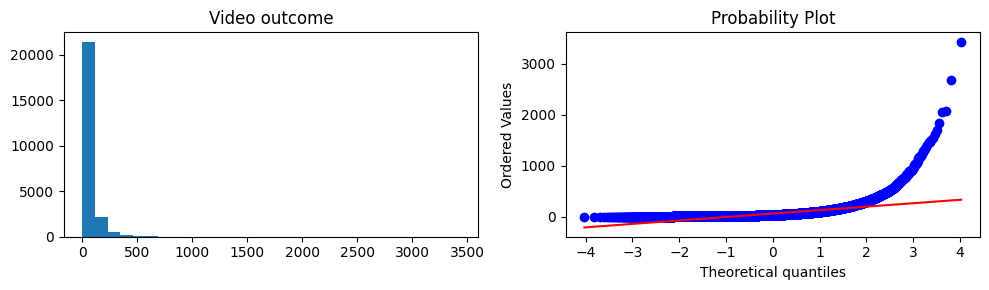

Methods: Welch t for continuous means; large-sample proportion z for binary; bootstrap for skewed watch time. Binary normality is not required.


In [ ]:
bad=raw.groupby(['experiment','user_id']).group.transform('nunique')>1
s1=raw.loc[~bad].copy(); s2=s1.loc[~s1.bot & ~((s1.experiment=='Video') & s1.idle)].copy(); clean=s2.dropna(subset=['outcome']).copy()
show('audit',[dict(stage=name,rows=len(d),missing=d.outcome.isna().sum()) for name,d in [('raw',raw),('conflicts removed',s1),('flags removed',s2),('complete cases',clean)]])
for name,d in [('raw',raw),('clean',clean)]: display(d.groupby(['experiment','group']).outcome.agg(['count','mean','std']))
for e,d in clean.groupby('experiment'):
    print(e); display(pd.crosstab(d.country,d.group,normalize='columns')); display(pd.crosstab(d.device,d.group,normalize='columns')); display(d.groupby('group').earlier_courses.mean())
    fig,ax=plt.subplots(1,2,figsize=(10,3)); ax[0].hist(d.outcome,bins=30); ax[0].set_title(e+' outcome'); stats.probplot(d.outcome,plot=ax[1]); plot('distribution_'+e)
print('Methods: Welch t for continuous means; large-sample proportion z for binary; bootstrap for skewed watch time. Binary normality is not required.')
clean.to_csv(OUT/'clean.csv',index=False)


## Task 3 — Point estimates and variability

,experiment,control,treatment,difference,SE_control,SE_treatment,SE_difference,bootstrap_SE
0,Onboarding,0.35241,0.37875,0.02635,0.00421,0.00444,0.00612,0.00616
1,Video,60.37394,61.23707,0.86313,0.84118,0.88938,1.22417,1.20845
2,Quiz,64.96540,65.95869,0.99330,0.11165,0.11759,0.16215,0.16086
3,Reminder,0.42551,0.42272,-0.00279,0.00434,0.00454,0.00628,0.00622


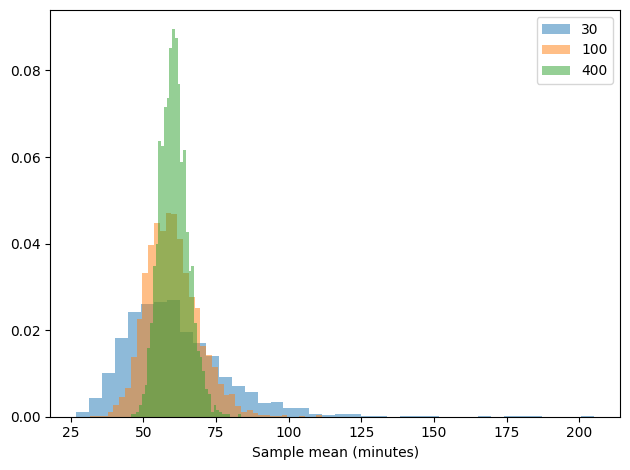

,n,mean_bias,mean_variance,population_variance,variance_n,variance_n_minus_1
0,30,0.91940,330.81621,9057.06339,9443.55268,9769.19243
1,100,-0.30318,82.41769,9057.06339,8201.71734,8284.56297
2,400,0.13731,22.99110,9057.06339,9105.30935,9128.12967


In [ ]:
def groups(e):
    d=clean[clean.experiment==e]; return tuple(d.loc[d.group==g,'outcome'].to_numpy() for g in [0,1])
def se(x): return x.std(ddof=1)/np.sqrt(len(x))
def bootmean(x,B=2000):
    return np.concatenate([rng.choice(x,(min(100,B-i),len(x)),replace=True).mean(axis=1) for i in range(0,B,100)])
rows=[]; boots={}
for e in spec:
    a,b=groups(e); ba,bb=bootmean(a),bootmean(b); boots[e]=bb-ba
    rows.append(dict(experiment=e,control=a.mean(),treatment=b.mean(),difference=b.mean()-a.mean(),SE_control=se(a),SE_treatment=se(b),SE_difference=np.hypot(se(a),se(b)),bootstrap_SE=boots[e].std(ddof=1)))
show('estimates',rows)
x=groups('Video')[0]; sim=[]
for size in [30,100,400]:
    s=rng.choice(x,(2000,size)); means=s.mean(axis=1); plt.hist(means,bins=40,alpha=.5,density=True,label=str(size)); sim.append(dict(n=size,mean_bias=means.mean()-x.mean(),mean_variance=means.var(),population_variance=x.var(),variance_n=s.var(axis=1).mean(),variance_n_minus_1=s.var(axis=1,ddof=1).mean()))
plt.legend(); plt.xlabel('Sample mean (minutes)'); plot('sampling'); show('variance_simulation',sim)


## Task 4 — Confidence intervals
Confidence describes long-run coverage of a procedure, not the probability that the fixed parameter lies in this particular computed interval.

In [ ]:
def interval(a,b,level=.95,binary=False):
    va=a.var(ddof=1)/len(a); vb=b.var(ddof=1)/len(b); sd=np.sqrt(va+vb); df=(va+vb)**2/(va**2/(len(a)-1)+vb**2/(len(b)-1)); q=stats.norm.ppf((1+level)/2) if binary else stats.t.ppf((1+level)/2,df); d=b.mean()-a.mean(); return d-q*sd,d+q*sd
def single(x,level,binary):
    q=stats.norm.ppf((1+level)/2) if binary else stats.t.ppf((1+level)/2,len(x)-1); return np.array([x.mean()-q*se(x),x.mean()+q*se(x)])
ci=[]
for e,(typ,h) in spec.items():
    a,b=groups(e)
    for level in [.9,.95,.99]:
        for name,bounds in [('control',single(a,level,typ=='binary')),('treatment',single(b,level,typ=='binary')),('difference',interval(a,b,level,typ=='binary'))]: ci.append(dict(experiment=e,level=level,estimate=name,lower=bounds[0],upper=bounds[1]))
show('confidence_intervals',ci)
boot_ci=np.quantile(boots['Video'],[.025,.975]); t_ci=interval(*groups('Video')); print('Watch difference bootstrap',boot_ci,'Welch',t_ci)
coverage=[]
for e in ['Video','Quiz']:
    x=groups(e)[0]
    for size in [30,100,400]:
        s=rng.choice(x,(1000,size)); mu=s.mean(1); err=s.std(1,ddof=1)/np.sqrt(size)
        for level in [.9,.95,.99]:
            half=stats.t.ppf((1+level)/2,size-1)*err; coverage.append(dict(metric=e,n=size,level=level,coverage=(abs(mu-x.mean())<=half).mean(),width=2*half.mean()))
show('coverage',coverage)


,experiment,level,estimate,lower,upper
0,Onboarding,0.90,control,0.34548,0.35933
1,Onboarding,0.90,treatment,0.37146,0.38605
2,Onboarding,0.90,difference,0.01628,0.03641
3,Onboarding,0.95,control,0.34415,0.36066
4,Onboarding,0.95,treatment,0.37006,0.38744
5,Onboarding,0.95,difference,0.01436,0.03833
6,Onboarding,0.99,control,0.34156,0.36326
7,Onboarding,0.99,treatment,0.36733,0.39018
8,Onboarding,0.99,difference,0.01059,0.04210
9,Video,0.90,control,58.99022,61.75765


Watch difference bootstrap [-1.48399828  3.22959633] Welch (np.float64(-1.536314149406325), np.float64(3.262572042441024))


,metric,n,level,coverage,width
0,Video,30,0.90,0.816,48.81985
1,Video,30,0.95,0.854,58.76418
2,Video,30,0.99,0.919,79.19735
3,Video,100,0.90,0.849,28.84924
4,Video,100,0.95,0.899,34.47570
5,Video,100,0.99,0.957,45.63370
6,Video,400,0.90,0.887,15.17019
7,Video,400,0.95,0.923,18.08930
8,Video,400,0.99,0.971,23.81515
9,Quiz,30,0.90,0.898,7.34860


## Task 5 — Testing using confidence intervals
Separate group interval overlap is not a valid test of the difference. A practical effect is established only if the entire difference interval lies beyond the business threshold.

In [ ]:
decisions=[]
for e,(typ,h) in spec.items():
    a,b=groups(e); lo,hi=interval(a,b,binary=typ=='binary'); ca=single(a,.95,typ=='binary'); cb=single(b,.95,typ=='binary'); sig=lo>0 or hi<0
    label='practically important' if lo>h or hi< -h else 'significant but below threshold' if sig and lo>=-h and hi<=h else 'inconclusive practical importance' if sig else 'inconclusive'
    decisions.append(dict(experiment=e,difference=b.mean()-a.mean(),lower=lo,upper=hi,reject_H0=sig,separate_intervals_overlap=max(ca[0],cb[0])<=min(ca[1],cb[1]),classification=label))
show('decisions',decisions)


,experiment,difference,lower,upper,reject_H0,separate_intervals_overlap,classification
0,Onboarding,0.02635,0.01436,0.03833,True,False,inconclusive practical importance
1,Video,0.86313,-1.53631,3.26257,False,True,inconclusive
2,Quiz,0.99330,0.67548,1.31112,True,False,significant but below threshold
3,Reminder,-0.00279,-0.01509,0.00952,False,True,inconclusive


## Task 6 — p-values
A p-value is the probability, under H0 and the test assumptions, of a statistic at least as extreme as observed. It is not the probability H0 is true or the probability the result occurred by chance. Type I: falsely launch a change; Type II: miss a genuine effect.

In [ ]:
def test(a,b,binary=False):
    d=b.mean()-a.mean()
    if binary:
        pooled=(a.sum()+b.sum())/(len(a)+len(b)); z=d/np.sqrt(pooled*(1-pooled)*(1/len(a)+1/len(b))); p=2*stats.norm.sf(abs(z)); software=stats.chi2_contingency([[a.sum(),len(a)-a.sum()],[b.sum(),len(b)-b.sum()]],correction=False).pvalue
    else:
        va=a.var(ddof=1)/len(a); vb=b.var(ddof=1)/len(b); z=d/np.sqrt(va+vb); df=(va+vb)**2/(va**2/(len(a)-1)+vb**2/(len(b)-1)); p=2*stats.t.sf(abs(z),df); software=stats.ttest_ind(b,a,equal_var=False).pvalue
    return z,p,software
results=[]
for e,(typ,h) in spec.items():
    z,p,sw=test(*groups(e),typ=='binary'); results.append(dict(experiment=e,statistic=z,p_formula=p,p_scipy=sw,reject=p<.05))
show('tests',results)
print('CI agreement:',[r['reject']==d['reject_H0'] for r,d in zip(results,decisions)])
# Under a random split of pooled outcomes the null is imposed without opening truth file.
for e in ['Video','Reminder']:
    x=np.concatenate(groups(e)); ps=[]
    for i in range(1000):
        s=rng.permutation(x); a,b=s[:len(s)//2],s[len(s)//2:]; ps.append(test(a,b,spec[e][0]=='binary')[1])
    print(e,'random split false-positive rate',np.mean(np.array(ps)<.05))
for alpha in [.01,.05,.1]:
    z=stats.norm.ppf(1-alpha/2); power=stats.norm.sf(z-2)+stats.norm.cdf(-z-2); print('alpha',alpha,'Type II at standardized noncentrality 2:',1-power)
a,b=groups('Video'); print('Raw-scale p',test(a,b)[1],'log-scale p (different estimand)',test(np.log1p(a),np.log1p(b))[1]); print('Small skewed samples Welch p:',test(a[:20],b[:20])[1])


,experiment,statistic,p_formula,p_scipy,reject
0,Onboarding,4.30802,0.00002,0.00002,True
1,Video,0.70507,0.48077,0.48077,False
2,Quiz,6.12589,0.00000,0.00000,True
3,Reminder,-0.44383,0.65717,0.65717,False


CI agreement: [np.True_, np.True_, np.True_, np.True_]
Video random split false-positive rate 0.058
Reminder random split false-positive rate 0.047
alpha 0.01 Type II at standardized noncentrality 2: 0.717632346039796
alpha 0.05 Type II at standardized noncentrality 2: 0.4839947260238252
alpha 0.1 Type II at standardized noncentrality 2: 0.361106196673066
Raw-scale p 0.4807707270722391 log-scale p (different estimand) 0.3674600632738515
Small skewed samples Welch p: 0.7649060309568554


## Task 7 — Practical significance and sample size
Equal allocation, 80% power and alpha .05; cost assumption ₹2 per learner. Formula is a planning approximation using observed variance.

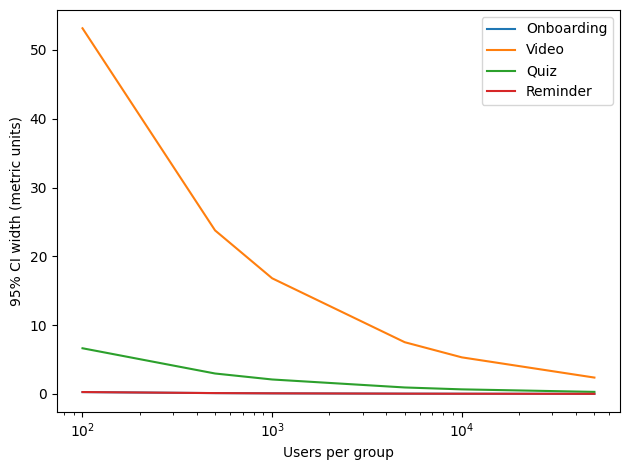

,experiment,effect,standardized_effect,n_per_group,cost_INR
0,Onboarding,0.02635,0.05472,9096,36384
1,Video,0.86313,0.00900,5772,23088
2,Quiz,0.99330,0.08296,563,2252
3,Reminder,-0.00279,-0.00564,9586,38344


Illustrative 12 million learners, tiny difference 0.1 p 0.0687618539185467


In [ ]:
planning=[]
for e,(typ,h) in spec.items():
    a,b=groups(e); sd=np.sqrt((a.var(ddof=1)+b.var(ddof=1))/2); n=int(np.ceil(2*sd**2*(stats.norm.ppf(.975)+stats.norm.ppf(.8))**2/h**2)); planning.append(dict(experiment=e,effect=b.mean()-a.mean(),standardized_effect=(b.mean()-a.mean())/sd,n_per_group=n,cost_INR=4*n)); sizes=np.array([100,500,1000,5000,10000,50000]); plt.plot(sizes,2*1.96*sd*np.sqrt(2/sizes),label=e)
plt.xscale('log'); plt.xlabel('Users per group'); plt.ylabel('95% CI width (metric units)'); plt.legend(); plot('width'); show('sample_size',planning)
x=groups('Video')[0]; tiny=.1; z=tiny/(x.std()*np.sqrt(2/6_000_000)); print('Illustrative 12 million learners, tiny difference',tiny,'p',2*stats.norm.sf(abs(z)))


## Task 8 — Multiple testing and peeking

First null experiment significant metrics: 0
Mean significant metrics: 0.9908
Family error uncorrected / Bonferroni: 0.638 0.0444
Power uncorrected / corrected: 0.7952 0.407
Peeking false-positive rate: 0.2544 fixed final: 0.0468


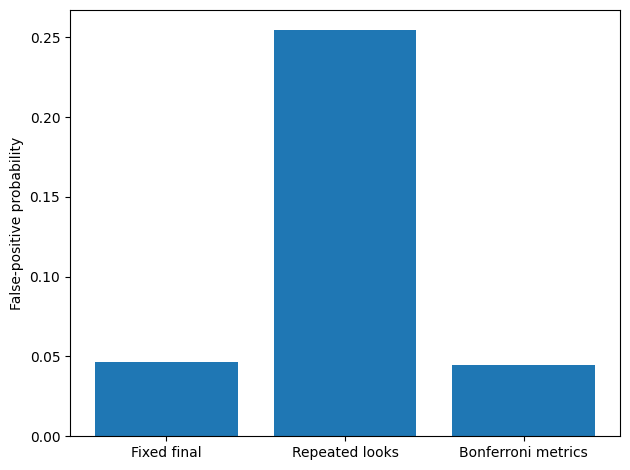

In [ ]:
z=rng.normal(size=(5000,20)); p=2*stats.norm.sf(abs(z)); print('First null experiment significant metrics:',(p[0]<.05).sum()); print('Mean significant metrics:',(p<.05).sum(1).mean()); print('Family error uncorrected / Bonferroni:',(p<.05).any(1).mean(),(p<.05/20).any(1).mean()); alt=2*stats.norm.sf(abs(rng.normal(2.8,1,5000))); print('Power uncorrected / corrected:',(alt<.05).mean(),(alt<.05/20).mean())
looks=20; increments=rng.normal(size=(5000,looks)); zs=increments.cumsum(1)/np.sqrt(np.arange(1,looks+1)); peek=2*stats.norm.sf(abs(zs)); print('Peeking false-positive rate:',(peek<.05).any(1).mean(),'fixed final:',(peek[:,-1]<.05).mean())
plt.bar(['Fixed final','Repeated looks','Bonferroni metrics'],[(peek[:,-1]<.05).mean(),(peek<.05).any(1).mean(),(p<.05/20).any(1).mean()]); plt.ylabel('False-positive probability'); plot('pitfalls')


## Task 9 — Predict then test
Predictions were saved before generating data. Compare the observed numbers below, noting random variation and that the width ratio assumes unchanged variance.

In [ ]:
print(predictions); print('Bootstrap width',np.diff(boot_ci)[0],'Welch width',np.diff(t_ci)[0]); print('Null metric count',(p[0]<.05).sum() if isinstance(p,np.ndarray) else 'see Task 8'); print('Width ratio',1/np.sqrt(2)); print('Significant experiments',[r['experiment'] for r in results if r['reject']])


{'bootstrap': 'Similar; bootstrap may be wider due to skew', 'metrics': 'About one of 20', 'width': '0.707 times when n doubles', 'significance': 'Onboarding and Quiz predicted, without inspecting outcomes'}
Bootstrap width 4.713594609650961 Welch width 4.798886191847349
Null metric count 0
Width ratio 0.7071067811865475
Significant experiments ['Onboarding', 'Quiz']


## Task 10 — Interpret, integrate and recommend
Pre-register primary metric, exclusions, alpha, sample size and fixed stopping date. Do not selectively report results. Obtain appropriate consent, minimize personal data, check fairness across groups and monitor harm. Synthetic results cannot justify real product changes.

In [ ]:
for d,r in zip(decisions,results):
    action='Consider adoption if safety checks pass' if d['lower']>spec[d['experiment']][1] else 'Stop or redesign if harmful or too small' if d['upper']< -spec[d['experiment']][1] or d['classification']=='significant but below threshold' else 'Continue only under a new pre-planned study if worthwhile'
    print(d['experiment'], 'effect',round(d['difference'],4),'95% CI',round(d['lower'],4),round(d['upper'],4),'p',round(r['p_formula'],6),action)


Onboarding effect 0.0263 95% CI 0.0144 0.0383 p 1.6e-05 Continue only under a new pre-planned study if worthwhile
Video effect 0.8631 95% CI -1.5363 3.2626 p 0.480771 Continue only under a new pre-planned study if worthwhile
Quiz effect 0.9933 95% CI 0.6755 1.3111 p 0.0 Stop or redesign if harmful or too small
Reminder effect -0.0028 95% CI -0.0151 0.0095 p 0.657167 Continue only under a new pre-planned study if worthwhile


## Task 11 — Day-4 design challenge
REDESIGN: 12 million learners, 40 metrics, daily looks and institutional clustering invalidate naive independence and single-test error control. Simulate equal-size institutions randomized as clusters. Compare naive learner-level SE (ignores ICC) with institution-level SE, fixed final analysis and Bonferroni. The simulation is a scaled Gaussian proxy, not the full 12-million-row experiment; heavy skew should additionally be checked by institution bootstrap on real data.

In [ ]:
R=2000; msize=50; rho=.10; clusters_per_arm=100; metrics=40; days=10; design_effect=1+(msize-1)*rho
# Standardized cluster-level mean differences under known Gaussian variance.
Z=rng.normal(size=(R,days,metrics)).cumsum(1)/np.sqrt(np.arange(1,days+1))[None,:,None]
naive=Z*np.sqrt(design_effect); naive_p=2*stats.norm.sf(abs(naive)); revised_p=2*stats.norm.sf(abs(Z[:,-1,:])); crit=stats.norm.ppf(1-.05/(2*metrics))
show('redesign',[dict(method='Naive daily 40 metrics',family_error=(naive_p<.05).any(axis=(1,2)).mean(),marginal_coverage=(abs(naive[:,-1,0])<=1.96).mean()),dict(method='Cluster fixed Bonferroni',family_error=(revised_p<.05/metrics).any(1).mean(),marginal_coverage=(abs(Z[:,-1,0])<=crit).mean())])
# Smallest important standardized effect assumed 0.2; compare power at fixed final look.
shift=.2/np.sqrt(2*design_effect/(clusters_per_arm*msize)); alt=Z[:,-1,0]+shift
print('Power cluster primary .05:',(abs(alt)>1.96).mean(),'Bonferroni:',(abs(alt)>crit).mean()); print('Design effect:',design_effect,'effective sample size:',2*clusters_per_arm*msize/design_effect)
print('Use one preregistered primary metric where possible; cluster bootstrap for heavy tails; secondary outcomes adjusted; wait until fixed endpoint unless a valid sequential rule is registered. Waiting delays deployment but protects error control.')


,method,family_error,marginal_coverage
0,Naive daily 40 metrics,1.0000,0.5855
1,Cluster fixed Bonferroni,0.0415,0.9985


Power cluster primary .05: 0.9815 Bonferroni: 0.8125
Design effect: 5.9 effective sample size: 1694.915254237288
Use one preregistered primary metric where possible; cluster bootstrap for heavy tails; secondary outcomes adjusted; wait until fixed endpoint unless a valid sequential rule is registered. Waiting delays deployment but protects error control.


## Reveal true effects (only after analysis)

In [ ]:
truth=json.loads((OUT/'true_effects.json').read_text()); print(truth)
show('truth_comparison',[dict(experiment=r['experiment'],true_generator_shift=truth[r['experiment']],observed_significant=r['reject'],observed_effect=d['difference']) for r,d in zip(results,decisions)])
print('Quiz clipping means the latent generator shift is approximate on observed score scale.')


{'Onboarding': 0.025, 'Video': 0, 'Quiz': 1.0, 'Reminder': 0}


,experiment,true_generator_shift,observed_significant,observed_effect
0,Onboarding,0.025,True,0.02635
1,Video,0.000,False,0.86313
2,Quiz,1.000,True,0.99330
3,Reminder,0.000,False,-0.00279


Quiz clipping means the latent generator shift is approximate on observed score scale.
